# Práctica 3 - Exploración de un dataset con pandas

## Objetivos

En esta práctica trabajarás con un dataset de clientes utilizando Python.

Al finalizar deberás ser capaz de:

- cargar datos desde un archivo CSV
- trabajar con un `DataFrame` de pandas
- identificar muestras y variables
- consultar la estructura de un dataset
- calcular estadísticas descriptivas
- seleccionar y filtrar datos
- analizar variables categóricas
- crear visualizaciones sencillas
- identificar las características \(X\) y la variable objetivo \(y\)
- determinar qué tipo de problema de Machine Learning podría resolverse

> **Importante:** no debes entrenar ningún modelo de Machine Learning en esta práctica.

## Contexto

Una empresa de telecomunicaciones quiere analizar el comportamiento de sus clientes. Dispone de información histórica y conoce qué clientes terminaron abandonando el servicio.

El objetivo futuro será desarrollar un sistema capaz de predecir:

> **¿Qué clientes tienen riesgo de abandonar la compañía?**

Para realizar la práctica utilizaremos el archivo `clientes.csv`.

| Variable | Descripción |
|---|---|
| `cliente_id` | Identificador del cliente |
| `edad` | Edad del cliente |
| `antiguedad` | Meses como cliente |
| `cuota_mensual` | Cuota mensual en euros |
| `consumo_datos` | Consumo mensual de datos en GB |
| `llamadas_soporte` | Número de llamadas a soporte |
| `incidencias` | Número de incidencias registradas |
| `tipo_contrato` | Mensual, anual o bienal |
| `satisfaccion` | Valoración del servicio de 1 a 5 |
| `abandono` | Indica si el cliente abandonó: Sí/No |

Cada fila corresponde a un cliente.

### Instrucciones

Completa las celdas de código marcadas con `# TODO`.

Cuando se solicite una interpretación, escribe tu respuesta en la celda Markdown correspondiente. No basta con ejecutar código: debes **interpretar los resultados**.

## Parte 1 - Preparación del entorno

### Ejercicio 1 - Importación

Importa NumPy, pandas y Matplotlib utilizando los alias convencionales.

In [6]:
# Importación de bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Respuesta

Explica brevemente para qué utilizaremos cada biblioteca:

- **NumPy:** para realizar operaciones numéricas y trabajar con arrays.
- **pandas:** para cargar, organizar, explorar y analizar los datos en DataFrames.
- **Matplotlib:** para crear gráficos y visualizar los datos.

## Parte 2 - Carga e inspección inicial

### Ejercicio 2 - Cargar el dataset

Carga `clientes.csv` en un DataFrame denominado `df` y muestra sus primeras filas.

In [7]:
# TODO: carga el archivo clientes.csv en df
df = pd.read_csv('clientes.csv')
# TODO: muestra las primeras filas
df.head()

,cliente_id,edad,antiguedad,cuota_mensual,consumo_datos,llamadas_soporte,incidencias,tipo_contrato,satisfaccion,abandono
0,10001,23,61.0,32.16,11.9,1,2,Mensual,1,No
1,10002,62,79.0,45.71,17.4,2,0,Anual,2,No
2,10003,55,49.0,60.48,14.6,0,1,Mensual,5,No
3,10004,43,6.0,116.82,21.8,4,0,Anual,3,No
4,10005,43,70.0,36.13,8.8,2,2,Anual,1,Sí


### Respuesta

**¿Qué representa cada fila del DataFrame?**

Cada fila representa un cliente de la empresa de telecomunicaciones.

**¿Qué representa cada columna?**

Cada columna representa una característica o variable del cliente

### Ejercicio 3 - Dimensiones

Obtén mediante código las dimensiones del dataset.

In [8]:
# TODO: muestra las dimensiones del DataFrame
df.shape

(180, 10)

### Respuesta

- **Número de muestras:** 180 clientes
- **Número de variables:** 10 columnas

### Ejercicio 4 - Columnas

Obtén mediante código los nombres de todas las columnas.

In [9]:
# TODO: muestra los nombres de las columnas
df.columns

Index(['cliente_id', 'edad', 'antiguedad', 'cuota_mensual', 'consumo_datos',
       'llamadas_soporte', 'incidencias', 'tipo_contrato', 'satisfaccion',
       'abandono'],
      dtype='str')

### Respuesta

**¿Qué columna parece representar la variable que queremos predecir? ¿Por qué?**

La columna `abandono` es la variable objetivo, porque indica si el cliente dejó el servicio con un `Sí` o `No` y es precisamente lo que la empresa quiere predecir.

### Ejercicio 5 - Tipos de datos

Obtén los tipos de datos de todas las columnas.

In [10]:
# TODO: consulta los tipos de datos
df.dtypes

cliente_id            int64
edad                  int64
antiguedad          float64
cuota_mensual       float64
consumo_datos       float64
llamadas_soporte      int64
incidencias           int64
tipo_contrato           str
satisfaccion          int64
abandono                str
dtype: object

### Respuesta

**Variables numéricas:**

cliente_id, edad, antiguedad, cuota_mensual, consumo_datos, llamadas_soporte, incidencias, satisfaccion

**Variables categóricas:**

tipo_contrato, abandono

**¿`cliente_id` debería considerarse una característica numérica simplemente porque contiene números? Razona la respuesta.**

No. cliente_id es un identificador único del cliente, no una variable.

## Parte 3 - Estructura y calidad inicial

### Ejercicio 6 - Información general

Utiliza `info()` para analizar la estructura del dataset.

In [11]:
# TODO: muestra la información general del DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cliente_id        180 non-null    int64  
 1   edad              180 non-null    int64  
 2   antiguedad        178 non-null    float64
 3   cuota_mensual     180 non-null    float64
 4   consumo_datos     179 non-null    float64
 5   llamadas_soporte  180 non-null    int64  
 6   incidencias       180 non-null    int64  
 7   tipo_contrato     180 non-null    str    
 8   satisfaccion      180 non-null    int64  
 9   abandono          180 non-null    str    
dtypes: float64(3), int64(5), str(2)
memory usage: 14.2 KB


### Respuesta

- ¿Cuántas entradas contiene?
  - El DataFrame tiene 180 filas y 10 columnas, así que contiene 180 registros.
- ¿Qué tipos de datos aparecen?
  - Hay columnas con tipos int64, float64 y texto string.
- ¿Todas las columnas contienen el mismo número de valores no nulos?
  - No. antiguedad tiene 178 valores no nulos y consumo_datos tiene 179.
- ¿Parece existir algún valor ausente?
  - Sí, Porque el número de valores no nulos no coincide con el total de filas en algunas columnas.
- ¿Cómo puedes deducirlo a partir de `info()`?
  - A partir de info() se ve que el recuento de valores no nulos es menor que el número total de filas en algunas columnas, lo que indica que faltan datos.


## Parte 4 - Estadística descriptiva

### Ejercicio 7 - Descripción estadística

Obtén las estadísticas descriptivas de las variables numéricas.

In [12]:
# TODO: genera las estadísticas descriptivas
df.describe()

,cliente_id,edad,antiguedad,cuota_mensual,consumo_datos,llamadas_soporte,incidencias,satisfaccion
count,180.000000,180.000000,178.000000,180.000000,179.000000,180.000000,180.000000,180.000000
mean,10090.500000,47.283333,62.050562,71.185667,16.408380,1.705556,1.111111,3.016667
std,52.105662,15.929059,33.991071,29.279251,9.813719,1.249345,1.082563,1.423957
min,10001.000000,18.000000,1.000000,20.480000,1.200000,0.000000,0.000000,1.000000
25%,10045.750000,34.000000,34.000000,43.172500,9.800000,1.000000,0.000000,2.000000
50%,10090.500000,47.000000,61.000000,72.690000,14.300000,1.000000,1.000000,3.000000
75%,10135.250000,62.000000,91.750000,97.177500,20.400000,2.250000,2.000000,4.000000
max,10180.000000,75.000000,120.000000,119.440000,54.200000,6.000000,5.000000,5.000000


### Interpretación

A partir del resultado, indica:

- edad media: alrededor de 47.3 años;
- edad mínima: 18 años;
- edad máxima: 75 años;
- cuota mensual media: aproximadamente 71.19 €;
- cuota mensual máxima: 119.44 €;
- media de llamadas a soporte: 1.71 llamadas por cliente;
- media de incidencias: 1.11 incidencias por cliente;
- satisfacción media: 3.02 puntos sobre 5.

La muestra tiene clientes con una media de 47 años. La cuota mensual en torno a 71 €. Las llamadas y las incidencias estan entre 1 y 2 por cliente, y la satisfacción media es de 3 sobre 5.


### Ejercicio 8 - Cálculos individuales

Calcula mediante instrucciones independientes los valores solicitados.

In [13]:
# TODO: media de edad
print(f"Media de edad: {df['edad'].mean():.3f}")

# TODO: mediana de edad
print(f"Mediana de edad: {df['edad'].median():.1f}")

# TODO: cuota mínima
print(f"Cuota mínima: {df['cuota_mensual'].min():.2f}")

# TODO: cuota máxima
print(f"Cuota máxima: {df['cuota_mensual'].max():.2f}")

# TODO: número total de incidencias
print(f"Número total de incidencias: {df['incidencias'].sum()}")

# TODO: satisfacción media
print(f"Satisfacción media: {df['satisfaccion'].mean():.3f}")

Media de edad: 47.283
Mediana de edad: 47.0
Cuota mínima: 20.48
Cuota máxima: 119.44
Número total de incidencias: 200
Satisfacción media: 3.017


### Comprobación

¿Coinciden estos resultados con los obtenidos mediante `describe()` cuando corresponde?

Sí. Los valores calculados por separado coinciden con los que aparecen en `describe()`


## Parte 5 - Selección de información

### Ejercicio 9 - Selección de columnas

Crea un DataFrame `df_clientes` que contenga únicamente `edad`, `antiguedad`, `cuota_mensual`, `satisfaccion` y `abandono`. Muestra sus primeras cinco filas.

In [14]:
# TODO: crea df_clientes
filtro = ['edad', 'antiguedad', 'cuota_mensual', 'satisfaccion', 'abandono']
df_clientes = df[filtro]

# TODO: muestra las primeras cinco filas
df_clientes.head()

,edad,antiguedad,cuota_mensual,satisfaccion,abandono
0,23,61.0,32.16,1,No
1,62,79.0,45.71,2,No
2,55,49.0,60.48,5,No
3,43,6.0,116.82,3,No
4,43,70.0,36.13,1,Sí


### Respuesta

**¿Sigue representando cada fila al mismo cliente que en el DataFrame original? Explica por qué.**

Sí. Cada fila sigue representando al mismo cliente que en el DataFrame original, porque se selecciona un subconjunto de columnas pero no se altera el orden ni se eliminan filas.

## Parte 6 - Filtrado

### Ejercicio 10 - Clientes por edad

Obtén todos los clientes mayores de 50 años y calcula cuántos cumplen la condición.

In [15]:
# TODO: filtra los clientes mayores de 50 años
filtro = df_clientes[df_clientes[ 'edad' ] > 50]
print([filtro])


# TODO: calcula cuántos son
print(f"La cantidad de clientes mayores de 50 años es: {filtro.shape[0]}")

[     edad  antiguedad  cuota_mensual  satisfaccion abandono
1      62        79.0          45.71             2       No
2      55        49.0          60.48             5       No
5      67         3.0         105.63             2       No
7      58       101.0          53.70             4       No
11     74        27.0          61.04             1       Sí
..    ...         ...            ...           ...      ...
172    62        96.0          35.35             3       Sí
173    59        65.0         104.90             2       No
174    58        66.0          95.67             4       No
176    59       119.0          74.58             3       No
178    70        61.0          94.18             3       Sí

[77 rows x 5 columns]]
La cantidad de clientes mayores de 50 años es: 77


### Ejercicio 11 - Clientes con incidencias

Selecciona los clientes que tengan `incidencias > 0` y determina cuántos son.

In [16]:
# TODO: filtra los clientes con incidencias
filtro_incidencias = df[df['incidencias'] > 0]
print(filtro_incidencias)


# TODO: calcula cuántos son
print(f"Clientes con incidencias: {filtro_incidencias.shape[0]}")

     cliente_id  edad  antiguedad  cuota_mensual  consumo_datos  \
0         10001    23        61.0          32.16           11.9   
2         10003    55        49.0          60.48           14.6   
4         10005    43        70.0          36.13            8.8   
5         10006    67         3.0         105.63           15.8   
6         10007    22        34.0          36.20           10.2   
..          ...   ...         ...            ...            ...   
169       10170    19       100.0          73.09            8.0   
173       10174    59        65.0         104.90           26.7   
174       10175    58        66.0          95.67           22.6   
175       10176    44        84.0         117.48           53.3   
178       10179    70        61.0          94.18           43.3   

     llamadas_soporte  incidencias tipo_contrato  satisfaccion abandono  
0                   1            2       Mensual             1       No  
2                   0            1       Mensua

### Ejercicio 12 - Condiciones combinadas

Obtén los clientes que cumplan simultáneamente:

\[
edad < 30
\]

y

\[
llamadas\_soporte \geq 3
\]

Muestra únicamente `cliente_id`, `edad`, `llamadas_soporte` y `abandono`.

In [17]:
# TODO: realiza el filtro y muestra únicamente las columnas solicitadas
filtro = df[(df['edad'] < 30) & (df['llamadas_soporte'] >= 3)]  
filtro = filtro[['cliente_id', 'edad', 'llamadas_soporte', 'abandono']]
print(filtro)
print(len(filtro))

     cliente_id  edad  llamadas_soporte abandono
17        10018    25                 3       No
22        10023    28                 3       No
35        10036    21                 3       Sí
55        10056    20                 3       No
101       10102    29                 3       No
117       10118    26                 3       Sí
119       10120    24                 3       No
132       10133    23                 4       No
146       10147    20                 3       No
167       10168    27                 6       Sí
169       10170    19                 3       Sí
11


### Respuesta

**¿Qué operador has utilizado para combinar ambas condiciones?**

He utilizado el operador &

### Ejercicio 13 - Segundo filtro combinado

Localiza clientes que cumplan:

\[
satisfaccion \leq 2
\]

y

\[
incidencias \geq 2
\]

Muestra las filas encontradas.

In [18]:
# TODO: realiza el filtro
filtro = df[(df['satisfaccion'] <= 2) & (df['incidencias'] >= 2)]
print(filtro)
print(len(filtro))

     cliente_id  edad  antiguedad  cuota_mensual  consumo_datos  \
0         10001    23        61.0          32.16           11.9   
4         10005    43        70.0          36.13            8.8   
5         10006    67         3.0         105.63           15.8   
11        10012    74        27.0          61.04            5.2   
19        10020    44        55.0          39.62            3.8   
20        10021    47        18.0          37.98           27.6   
24        10025    63        23.0          40.24            7.8   
25        10026    55        34.0          50.03           16.1   
35        10036    21       115.0          41.06           27.0   
44        10045    21       119.0          40.48           16.0   
46        10047    43        85.0         109.32           27.6   
50        10051    62         6.0          92.27            6.1   
59        10060    57        42.0          51.94            6.4   
61        10062    61        37.0          92.74           12.

### Reflexión

**Observando únicamente estos resultados, ¿podemos afirmar que una satisfacción baja provoca el abandono?**

No. Aunque los clientes con baja satisfacción y muchas incidencias puedan tener más probabilidades de abandonar, otros factores también pueden influir en la decisión de un cliente de dejar el servicio. Se necesitaría un análisis más profundo para establecer una relación causal.

## Parte 7 - Variables categóricas

### Ejercicio 14 - Tipo de contrato

Obtén los diferentes valores de `tipo_contrato` y calcula cuántos clientes pertenecen a cada categoría.

In [19]:
# TODO: muestra las categorías existentes
print(df['tipo_contrato'].unique())

# TODO: calcula la frecuencia de cada categoría
print(df['tipo_contrato'].value_counts())

<StringArray>
['Mensual', 'Anual', 'Bienal']
Length: 3, dtype: str
tipo_contrato
Mensual    94
Anual      56
Bienal     30
Name: count, dtype: int64


### Respuesta

**¿Cuál es el tipo de contrato más frecuente?**

Mensual

### Ejercicio 15 - Variable `abandono`

Obtén las categorías existentes, el número de clientes de cada categoría y sus frecuencias relativas.

In [20]:
# TODO: categorías existentes
print(df['abandono'].unique())

# TODO: frecuencias absolutas
print(df['abandono'].value_counts())

# TODO: frecuencias relativas
print(df['abandono'].value_counts(normalize=True))
print((df['abandono'].value_counts(normalize=True) * 100).round(2))

<StringArray>
['No', 'Sí']
Length: 2, dtype: str
abandono
No    110
Sí     70
Name: count, dtype: int64
abandono
No    0.611111
Sí    0.388889
Name: proportion, dtype: float64
abandono
No    61.11
Sí    38.89
Name: proportion, dtype: float64


### Interpretación

Expresa las frecuencias relativas mediante porcentajes y redacta una breve conclusión sobre la distribución de `abandono`.

- **No:** 110 clientes (61,11 %)
- **Sí:** 70 clientes (38,89 %)

La mayoría de los clientes no abandonó (61,11 %), aunque una proporción considerable, cercana al 39 %, sí lo hizo. Por tanto, la distribución está algo desequilibrada, con más clientes que permanecen que clientes que abandonan.

## Parte 8 - Visualización

Todos los gráficos deben contener como mínimo:

- título;
- etiquetas de los ejes cuando correspondan;
- una representación clara.

### Ejercicio 16 - Distribución de edad

Construye un histograma de `edad`.

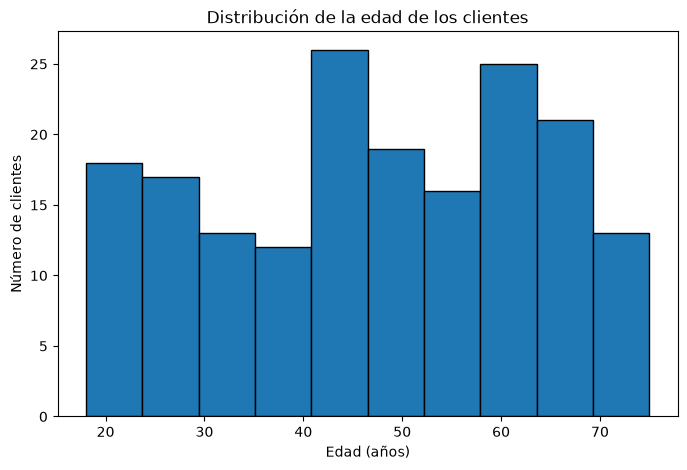

In [21]:
# TODO: crea el histograma de edad
plt.figure(figsize=(8, 5))
plt.hist(df['edad'], bins=10, edgecolor='black')
plt.title('Distribución de la edad de los clientes')
plt.xlabel('Edad (años)')
plt.ylabel('Número de clientes')
plt.show()

### Interpretación

**¿Qué información proporciona un histograma que no resulta tan fácil obtener observando directamente las filas del DataFrame?**

Un histograma muestra de un vistazo cómo se distribuyen los valores de la edad: entre qué valores se concentran más clientes, el rango (de 18 a 75 años), si la distribución es simétrica o asimétrica y si hay valores atípicos. Observando las filas una a una sería muy difícil hacerse esa idea global. En este caso, las edades están repartidas de forma bastante uniforme en todo el rango, sin un grupo de edad claramente dominante.

### Ejercicio 17 - Abandono

Representa mediante un gráfico de barras el número de clientes que abandonaron y que no abandonaron.

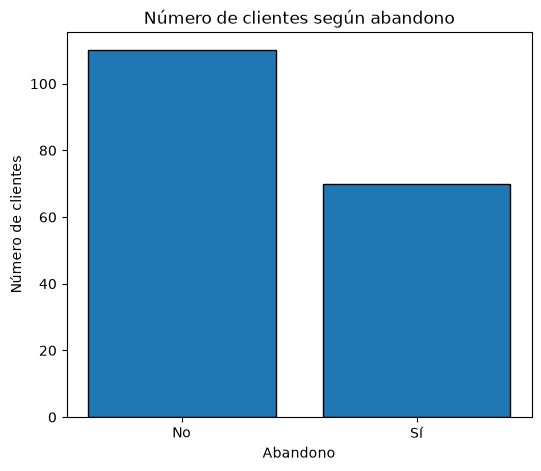

In [22]:
# TODO: crea el gráfico de barras
conteo_abandono = df['abandono'].value_counts()

plt.figure(figsize=(6, 5))
plt.bar(conteo_abandono.index, conteo_abandono.values, edgecolor='black')
plt.title('Número de clientes según abandono')
plt.xlabel('Abandono')
plt.ylabel('Número de clientes')
plt.show()

### Interpretación

Describe brevemente qué muestra el gráfico.

La barra de No (110 clientes) es claramente más alta que la de Si (70 clientes), por lo que la mayoría de los clientes permanecen en la compañía.

### Ejercicio 18 - Cuota mensual

Crea un histograma para `cuota_mensual`.

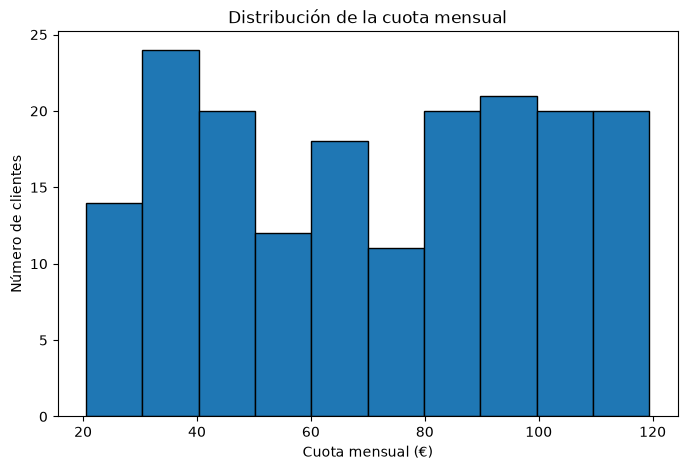

In [23]:
# TODO: crea el histograma de cuota_mensual
plt.figure(figsize=(8, 5))
plt.hist(df['cuota_mensual'], bins=10, edgecolor='black')
plt.title('Distribución de la cuota mensual')
plt.xlabel('Cuota mensual (€)')
plt.ylabel('Número de clientes')
plt.show()

### Interpretación

Analiza visualmente la distribución.

Las cuotas mensuales van aproximadamente de 20 € a 120 €. La distribución es bastante uniforme: todas las franjas tienen un número de clientes parecido.

### Ejercicio 19 - Edad y cuota

Crea un diagrama de dispersión utilizando:

\[
x = edad
\]

\[
y = cuota\_mensual
\]

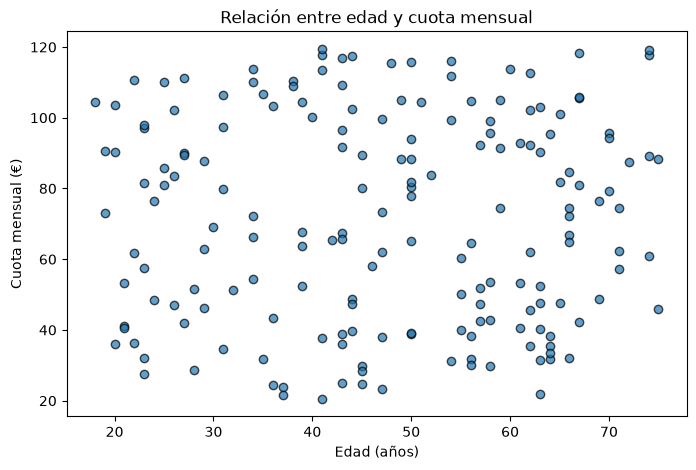

In [24]:
# TODO: crea el diagrama de dispersión
plt.figure(figsize=(8, 5))
plt.scatter(df['edad'], df['cuota_mensual'], alpha=0.7, edgecolor='black')
plt.title('Relación entre edad y cuota mensual')
plt.xlabel('Edad (años)')
plt.ylabel('Cuota mensual (€)')
plt.show()

### Interpretación

- ¿Qué representa cada punto?
- ¿Observas a simple vista alguna relación clara entre ambas variables?

No es necesario realizar un análisis estadístico.

- **¿Qué representa cada punto?** Cada punto es un cliente: su posición horizontal indica su edad y su posición vertical, la cuota mensual que paga.
- **¿Observas alguna relación clara?** No. Los puntos están repartidos de forma dispersa por todo el gráfico, sin seguir ninguna tendencia ascendente ni descendente.

## Parte 9 - Identificación de $X$ e $y$

La empresa quiere construir en el futuro un modelo que determine si un cliente abandonará.

### Ejercicio 20 - Variable objetivo

Identifica y crea `y`. Después muestra sus cinco primeros valores.

In [25]:
# TODO: crea y
y = df['abandono']


# TODO: muestra sus cinco primeros valores
y.head()

0    No
1    No
2    No
3    No
4    Sí
Name: abandono, dtype: str

### Respuesta

**¿Por qué esta variable corresponde a \(y\)?**

`y` es lo que queremos predecir: si el cliente abandona o no.

### Ejercicio 21 - Características

Crea `X` utilizando inicialmente estas características:

- `edad`
- `antiguedad`
- `cuota_mensual`
- `consumo_datos`
- `llamadas_soporte`
- `incidencias`
- `tipo_contrato`
- `satisfaccion`

Después comprueba sus dimensiones.

In [26]:
# TODO: crea X
X = df[['edad', 'antiguedad', 'cuota_mensual', 'consumo_datos',
       'llamadas_soporte', 'incidencias', 'tipo_contrato',
       'satisfaccion']]


# TODO: muestra las dimensiones de X
X.shape

(180, 8)

### Respuesta

Si el dataset contiene \(n\) clientes, esperamos:

\[
X.shape = (n,\ ?)
\]

**¿Qué número debe aparecer en `?`? ¿Por qué?**

Debe aparecer **8**, porque hemos elegido ocho características. `cliente_id` no cuenta y `abandono` es `y`.

## Parte 10 - Razonamiento de Machine Learning

### Ejercicio 22 - Identificación del problema

Queremos predecir:

`abandono → Sí / No`

Responde razonadamente:

1. ¿Estamos ante aprendizaje supervisado o no supervisado?
2. ¿Por qué?
3. ¿Es clasificación o regresión?
4. ¿Por qué?
5. ¿Es clasificación binaria o multiclase?
6. ¿Cuáles son las clases?

### Respuesta

Es aprendizaje supervisado porque conocemos el resultado (`abandono`).

Es clasificación binaria porque queremos predecir dos clases: `Sí` o `No`.

## Parte 11 - Un cambio en el problema

Supongamos ahora que la empresa plantea:

> Queremos predecir cuál será el **consumo de datos del próximo mes** de cada cliente.

### Ejercicio 23

Responde:

1. ¿Cuál sería ahora la variable objetivo?
2. ¿Seguiríamos teniendo exactamente el mismo \(X\)?
3. ¿Sería clasificación o regresión?
4. ¿Seguiría siendo aprendizaje supervisado?
5. Justifica cada respuesta.

### Respuesta

La variable objetivo sería el consumo del próximo mes. `X` no sería exactamente igual: usaríamos solo datos disponibles antes de ese mes.

Sería regresión porque el consumo es numérico y seguiría siendo aprendizaje supervisado porque conocemos consumos anteriores.

## Parte 12 - Análisis crítico

### Ejercicio 24 - ¿Utilizarías `cliente_id`?

Los identificadores tienen valores como:

`10001, 10002, 10003, 10004, ...`

¿Utilizarías esta columna como característica para predecir el abandono?

No respondas únicamente «sí» o «no». Razona tu decisión.

### Respuesta

No usaría `cliente_id`: solo identifica al cliente y no aporta información útil. Lo quitaría de `X`.

### Ejercicio 25 - ¿Estamos preparados para entrenar?

Después del análisis anterior, alguien propone ejecutar directamente:

```python
modelo.fit(X, y)
```

¿Estamos preparados?

Identifica **al menos cuatro cuestiones** que deberíamos estudiar o resolver antes de entrenar el modelo.

No necesitas explicar todavía cómo resolverlas.

### Respuesta

1. Tratar los valores ausentes.
2. Convertir `tipo_contrato` a números.
3. Separar datos de entrenamiento y prueba.
4. Elegir métricas y revisar el equilibrio de las clases.
5. Quitar identificadores y evitar fugas de información.

## Parte 13 - Conclusiones

### Ejercicio 26 - Informe final

Escribe entre **8 y 12 líneas** resumiendo lo que has descubierto.

Debes incluir como mínimo:

- tamaño del dataset
- principales tipos de variables
- comportamiento de `abandono`
- alguna observación de las estadísticas
- alguna observación de las visualizaciones
- cuáles son \(X\) e \(y\)
- tipo de problema de Machine Learning
- qué pasos deberían realizarse antes de entrenar

### Conclusiones

El dataset tiene 180 clientes y 10 variables.
Hay variables numéricas y categóricas.
`abandono` tiene dos valores: `Sí` y `No`.
La mayoría de clientes no abandonó.
La edad media es de unos 47 años y la cuota media de unos 71 euros.
Los histogramas muestran cómo se reparten las edades y las cuotas.
No se ve una relación clara entre edad y cuota.
`X` tiene ocho características y `y` es `abandono`.
Es un problema supervisado de clasificación binaria.
Antes de entrenar hay que tratar ausencias y preparar los datos.

---

# Ampliación opcional

Si terminas antes, investiga cómo obtener con pandas:

1. El número exacto de valores ausentes de cada columna.
2. El número de clientes agrupados por `tipo_contrato` y `abandono`.
3. La cuota mensual media de quienes abandonaron y de quienes no.
4. La satisfacción media de ambos grupos.

No utilices algoritmos de Machine Learning.

In [27]:
# AMPLIACIÓN OPCIONAL

# 1. Valores ausentes por columna
print(df.isna().sum())


# 2. Clientes agrupados por tipo_contrato y abandono
print(df.groupby(['tipo_contrato', 'abandono']).size())


# 3. Cuota mensual media según abandono
print(df.groupby('abandono')['cuota_mensual'].mean())


# 4. Satisfacción media según abandono
print(df.groupby('abandono')['satisfaccion'].mean())

cliente_id          0
edad                0
antiguedad          2
cuota_mensual       0
consumo_datos       1
llamadas_soporte    0
incidencias         0
tipo_contrato       0
satisfaccion        0
abandono            0
dtype: int64
tipo_contrato  abandono
Anual          No          36
               Sí          20
Bienal         No          20
               Sí          10
Mensual        No          54
               Sí          40
dtype: int64
abandono
No    71.254727
Sí    71.077143
Name: cuota_mensual, dtype: float64
abandono
No    3.345455
Sí    2.500000
Name: satisfaccion, dtype: float64


# Antes de entregar

Comprueba que:

- has completado todas las celdas `TODO`
- has respondido las preguntas en Markdown
- todos los gráficos tienen título y etiquetas
- has reiniciado el entorno y ejecutado el notebook completo desde el principio
- no se producen errores
- no has entrenado ningún modelo

**Nombre recomendado del archivo de entrega:**

`Practica_03_Apellido_Nombre.ipynb`